# Session 11: Data Handling Using Pandas

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in []:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-11_series_dataframe.py`

In [2]:
"""
Session 11 · Example 1: pandas Series and DataFrame - create, inspect, select
-----------------------------------------------------------------------------
Run:  python session-11_series_dataframe.py
"""
import numpy as np
import pandas as pd

pd.set_option("display.width", 110)

# 1. Series: a 1-D labelled array (values + index)
temps = pd.Series([31, 33, 35, 34, 29], index=["Mon", "Tue", "Wed", "Thu", "Fri"], name="max_temp_C")
print(temps, "\n")
print("temps['Wed'] =", temps["Wed"], "| temps.iloc[0] =", temps.iloc[0], "| mean =", temps.mean())
print("hot days (> 32):", temps[temps > 32].to_dict())
print("vectorised maths, to Fahrenheit:", (temps * 9 / 5 + 32).round(1).tolist())
print("Series from a dict:", pd.Series({"Karachi": 20.4, "Lahore": 13.0, "Quetta": 1.6}).to_dict())

# 2. DataFrame: a 2-D table of columns (each column is a Series)
df = pd.DataFrame({
    "roll": ["AI-01", "AI-02", "AI-03", "AI-04", "AI-05", "AI-06"],
    "name": ["Ali", "Sana", "Bilal", "Hira", "Omar", "Zara"],
    "city": ["Karachi", "Lahore", "Karachi", "Quetta", "Karachi", "Lahore"],
    "python": [78, 91, 64, 85, np.nan, 72],
    "stats": [70, 88, 59, 90, 66, 81],
})
print("\n", df)
print("\nshape:", df.shape, "| columns:", list(df.columns))
print("dtypes:\n" + df.dtypes.to_string())
print("\ndescribe():\n", df.describe().round(1))

# 3. Selecting columns and rows
print("\none column (Series):", df["name"].tolist())
print("two columns (DataFrame):\n", df[["name", "python"]].head(3))
df = df.set_index("roll")                          # use roll numbers as row labels
print("\nloc by label  df.loc['AI-04']:\n", df.loc["AI-04"].to_dict())
print("iloc by position df.iloc[0:2, 0:2]:\n", df.iloc[0:2, 0:2])
print("\nloc rows + columns:\n", df.loc[["AI-02", "AI-05"], ["name", "stats"]])

# 4. Boolean filtering (combine with & | ~ and parentheses)
karachi_good = df[(df["city"] == "Karachi") & (df["stats"] >= 60)]
print("\nKarachi students with stats >= 60:\n", karachi_good[["name", "stats"]])
print("isin:", df[df["city"].isin(["Lahore", "Quetta"])]["name"].tolist())
print("query():", df.query("python > 80 and stats > 80")["name"].tolist())

# 5. Adding and changing columns
df["total"] = df["python"].fillna(0) + df["stats"]
df["passed"] = df[["python", "stats"]].min(axis=1, skipna=False) >= 60   # a missing mark is not a pass
print("\nwith new columns:\n", df)

Mon    31
Tue    33
Wed    35
Thu    34
Fri    29
Name: max_temp_C, dtype: int64 

temps['Wed'] = 35 | temps.iloc[0] = 31 | mean = 32.4
hot days (> 32): {'Tue': 33, 'Wed': 35, 'Thu': 34}
vectorised maths, to Fahrenheit: [87.8, 91.4, 95.0, 93.2, 84.2]
Series from a dict: {'Karachi': 20.4, 'Lahore': 13.0, 'Quetta': 1.6}

     roll   name     city  python  stats
0  AI-01    Ali  Karachi    78.0     70
1  AI-02   Sana   Lahore    91.0     88
2  AI-03  Bilal  Karachi    64.0     59
3  AI-04   Hira   Quetta    85.0     90
4  AI-05   Omar  Karachi     NaN     66
5  AI-06   Zara   Lahore    72.0     81

shape: (6, 5) | columns: ['roll', 'name', 'city', 'python', 'stats']
dtypes:
roll          str
name          str
city          str
python    float64
stats       int64

describe():
        python  stats
count     5.0    6.0
mean     78.0   75.7
std      10.6   12.6
min      64.0   59.0
25%      72.0   67.0
50%      78.0   75.5
75%      85.0   86.2
max      91.0   90.0

one column (Series): ['Ali

## Example: `session-11_manipulation.py`

In [3]:
"""
Session 11 · Example 2: data manipulation - clean, sort, group, merge, reshape
-----------------------------------------------------------------------------
Run:  python session-11_manipulation.py
"""
import numpy as np
import pandas as pd

pd.set_option("display.width", 110)
orders = pd.DataFrame({
    "order_id": [101, 102, 103, 104, 105, 105, 106, 107, 108],
    "date": ["2026-10-01", "2026-10-01", "2026-10-02", "2026-10-02", "2026-10-03", "2026-10-03",
             "2026-10-03", "2026-10-04", None],
    "branch": ["Clifton", "Gulshan", "Clifton", "DHA", "Gulshan", "Gulshan", "DHA", "Clifton", "DHA"],
    "item": ["Biryani", "Karahi", "Biryani", "Nihari", "Biryani", "Biryani", "Karahi", "Nihari", "Biryani"],
    "qty": [2, 1, 3, np.nan, 1, 1, 2, 2, 4],
    "price": [450, 1450, 450, 600, 450, 450, 1450, 600, 450],
})
print("raw data:\n", orders, "\n")

# 1. Missing values and duplicates
print("missing per column:", orders.isna().sum().to_dict())
print("duplicated rows:", orders.duplicated().sum())
clean = (orders.drop_duplicates()                       # remove the repeated order 105
               .dropna(subset=["date"])                 # an order with no date cannot be dated
               .assign(qty=lambda d: d["qty"].fillna(1).astype(int),      # assume 1 if missing
                       date=lambda d: pd.to_datetime(d["date"])))
clean["revenue"] = clean["qty"] * clean["price"]
print("after cleaning:", clean.shape, "\n", clean)

# 2. Sorting
print("\ntop 3 by revenue:\n", clean.sort_values("revenue", ascending=False).head(3)[["order_id", "item", "revenue"]])

# 3. apply / map on columns
size = {"Biryani": "single dish", "Karahi": "family dish", "Nihari": "single dish"}
clean["type"] = clean["item"].map(size)
clean["band"] = clean["revenue"].apply(lambda r: "high" if r >= 1400 else "normal")
print("\nmap + apply:\n", clean[["item", "type", "revenue", "band"]])

# 4. groupby + aggregate (split - apply - combine)
by_branch = clean.groupby("branch").agg(orders=("order_id", "count"), units=("qty", "sum"),
                                        revenue=("revenue", "sum")).sort_values("revenue", ascending=False)
print("\nby branch:\n", by_branch)
print("\nmean revenue per item:", clean.groupby("item")["revenue"].mean().round(0).to_dict())

# 5. pivot_table: branches as rows, items as columns
print("\npivot (revenue):\n", clean.pivot_table(index="branch", columns="item", values="revenue",
                                              aggfunc="sum", fill_value=0, margins=True))

# 6. merge (SQL-style join) with a second table
managers = pd.DataFrame({"branch": ["Clifton", "Gulshan", "DHA", "Saddar"],
                         "manager": ["Mr Asif", "Ms Rabia", "Mr Junaid", "Ms Nida"]})
merged = by_branch.reset_index().merge(managers, on="branch", how="right")
print("\nmerge how='right' (Saddar has no orders yet):\n", merged.fillna({"orders": 0, "units": 0, "revenue": 0}))

# 7. concat: stack two days of new orders under the old ones
extra = pd.DataFrame({"order_id": [109], "date": [pd.Timestamp("2026-10-05")], "branch": ["DHA"],
                      "item": ["Karahi"], "qty": [1], "price": [1450], "revenue": [1450]})
print("\nafter concat:", len(pd.concat([clean, extra], ignore_index=True)), "rows")

# 8. Dates: extract parts and resample by day
daily = clean.set_index("date")["revenue"].resample("D").sum()
print("\ndaily revenue:", {d.strftime("%a %d"): int(v) for d, v in daily.items()})

raw data:
    order_id        date   branch     item  qty  price
0       101  2026-10-01  Clifton  Biryani  2.0    450
1       102  2026-10-01  Gulshan   Karahi  1.0   1450
2       103  2026-10-02  Clifton  Biryani  3.0    450
3       104  2026-10-02      DHA   Nihari  NaN    600
4       105  2026-10-03  Gulshan  Biryani  1.0    450
5       105  2026-10-03  Gulshan  Biryani  1.0    450
6       106  2026-10-03      DHA   Karahi  2.0   1450
7       107  2026-10-04  Clifton   Nihari  2.0    600
8       108         NaN      DHA  Biryani  4.0    450 

missing per column: {'order_id': 0, 'date': 1, 'branch': 0, 'item': 0, 'qty': 1, 'price': 0}
duplicated rows: 1
after cleaning: (7, 7) 
    order_id       date   branch     item  qty  price  revenue
0       101 2026-10-01  Clifton  Biryani    2    450      900
1       102 2026-10-01  Gulshan   Karahi    1   1450     1450
2       103 2026-10-02  Clifton  Biryani    3    450     1350
3       104 2026-10-02      DHA   Nihari    1    600      600


## Example: `session-11_text_processing.py`

In [4]:
"""
Session 11 · Example 3: text processing with the .str accessor
--------------------------------------------------------------
Every string method works on a whole column at once via Series.str,
including regular expressions (Session 6).
Run:  python session-11_text_processing.py
"""
import pandas as pd

pd.set_option("display.width", 120)
raw = pd.DataFrame({
    "name": ["  ali KHAN", "Sana  tariq ", "BILAL ahmed", "hira shah", "Omar   Farooq"],
    "email": ["Ali.Khan@Example.COM", "sana@uni.edu.pk", "bilal@@mail", "HIRA@example.com ", "omar.f@uni.edu.pk"],
    "phone": ["0300-1234567", "+92 321 7654321", "03451234567", "021-34567890", "0333 444 5566"],
    "address": ["House 12, Block 5, Clifton, Karachi", "Flat 3B, Gulberg III, Lahore",
                "Plot 7, Gulshan-e-Iqbal, Karachi", "Street 9, Satellite Town, Quetta", "Shop 4, Saddar, Karachi"],
    "feedback": ["Great course!!", "too fast, but useful", "Loved the Python labs", "boring slides", "great labs; fast pace"],
})

df = pd.DataFrame()
df["name"] = raw["name"].str.strip().str.split().str.join(" ").str.title()       # tidy spaces + Title Case
df["first"] = df["name"].str.split().str[0]
df["email"] = raw["email"].str.strip().str.lower()
df["email_ok"] = df["email"].str.match(r"^[\w.+-]+@[\w-]+(\.[\w-]+)+$")
df["domain"] = df["email"].str.extract(r"@([\w.-]+)$", expand=False)
digits = raw["phone"].str.replace(r"\D", "", regex=True)                       # keep digits only
df["mobile"] = digits.str.replace(r"^92", "0", regex=True).where(digits.str.match(r"^(92|0)3\d{9}$"))
df["mobile"] = df["mobile"].str.replace(r"^(\d{4})(\d{7})$", r"\1-\2", regex=True)
df["city"] = raw["address"].str.split(",").str[-1].str.strip()
df["area"] = raw["address"].str.split(",").str[-2].str.strip()
print(df.to_string(), "\n")

print("first names starting with a vowel:", df.loc[df["first"].str.contains(r"^[AEIOU]"), "first"].tolist())
print("name lengths:", df["name"].str.len().tolist())
print("starts with 'S' or 'O':", df.loc[df["name"].str.startswith(("S", "O")), "name"].tolist())
print("invalid emails:", df.loc[~df["email_ok"], "email"].tolist())
print("not a mobile number:", raw.loc[df["mobile"].isna(), "phone"].tolist())
print("students per city:", df["city"].value_counts().to_dict())

# Simple text analytics on feedback: normalise, tokenize, count words
words = (raw["feedback"].str.lower()
                        .str.replace(r"[^a-z\s]", " ", regex=True)
                        .str.split()
                        .explode())                                     # one word per row
stop = {"the", "but", "too"}
print("\ntop feedback words:", words[~words.isin(stop)].value_counts().head(5).to_dict())
print("mentions 'fast':", raw["feedback"].str.contains("fast").sum(), "of", len(raw))

          name  first                 email  email_ok       domain        mobile     city             area
0     Ali Khan    Ali  ali.khan@example.com      True  example.com  0300-1234567  Karachi          Clifton
1   Sana Tariq   Sana       sana@uni.edu.pk      True   uni.edu.pk  0321-7654321   Lahore      Gulberg III
2  Bilal Ahmed  Bilal           bilal@@mail     False         mail  0345-1234567  Karachi  Gulshan-e-Iqbal
3    Hira Shah   Hira      hira@example.com      True  example.com           NaN   Quetta   Satellite Town
4  Omar Farooq   Omar     omar.f@uni.edu.pk      True   uni.edu.pk  0333-4445566  Karachi           Saddar 

first names starting with a vowel: ['Ali', 'Omar']
name lengths: [8, 10, 11, 9, 11]
starts with 'S' or 'O': ['Sana Tariq', 'Omar Farooq']
invalid emails: ['bilal@@mail']
not a mobile number: ['021-34567890']
students per city: {'Karachi': 3, 'Lahore': 1, 'Quetta': 1}

top feedback words: {'great': 2, 'fast': 2, 'labs': 2, 'course': 1, 'useful': 1}
mentio

## Example: `session-11_problem_sales_analysis.py`

In [5]:
"""
Session 11 · Real-life problem: monthly sales analysis for a restaurant chain
----------------------------------------------------------------------------
PROBLEM
A restaurant chain with 3 Karachi branches exports one CSV row per order.
The export is messy: branch names in mixed case with spaces, prices stored as
text like "Rs 1,450", some missing quantities and duplicate order ids.
Management wants:
  1. a clean DataFrame,
  2. revenue per branch per month (pivot table),
  3. the best-selling item in each branch,
  4. the busiest weekday,
  5. a chart of monthly revenue by branch, and a clean CSV export.
The data is generated with a fixed random seed so the results are reproducible.
Run:  python session-11_problem_sales_analysis.py
"""
import numpy as np
import pandas as pd

pd.set_option("display.width", 110)
rng = np.random.default_rng(7)

# ---------- 1. create a realistic messy export (stands in for a real file) ----------
menu = {"Biryani": 450, "Chicken Karahi": 1450, "Nihari": 600, "Haleem": 400, "BBQ Platter": 1900}
n = 600
raw = pd.DataFrame({
    "order_id": np.arange(5001, 5001 + n),
    "date": pd.Timestamp("2026-07-01") + pd.to_timedelta(rng.integers(0, 92, n), unit="D"),
    "branch": rng.choice([" clifton", "Gulshan ", "DHA", "CLIFTON", "gulshan"], n),
    "item": rng.choice(list(menu), n, p=[0.32, 0.18, 0.2, 0.18, 0.12]),
    "qty": rng.integers(1, 5, n).astype(float),
})
raw["price"] = raw["item"].map(lambda i: f"Rs {menu[i]:,}")
raw.loc[rng.choice(n, 25, replace=False), "qty"] = np.nan          # missing quantities
raw = pd.concat([raw, raw.sample(12, random_state=1)])              # duplicated rows
raw.to_csv("sales_raw.csv", index=False)
print("raw export:", raw.shape, "| sample:\n", raw.head(3).to_string(index=False))

# ---------- 2. clean ----------
df = pd.read_csv("sales_raw.csv", parse_dates=["date"])
before = len(df)
df = df.drop_duplicates(subset="order_id")
df["branch"] = df["branch"].str.strip().str.title().replace({"Dha": "DHA"})   # title() would spoil the acronym
df["price"] = df["price"].str.replace(r"[^\d]", "", regex=True).astype(int)
df["qty"] = df["qty"].fillna(df.groupby("item")["qty"].transform("median")).astype(int)
df["revenue"] = df["qty"] * df["price"]
df["month"] = df["date"].dt.to_period("M").astype(str)
df["weekday"] = df["date"].dt.day_name()
print(f"\ncleaned: removed {before - len(df)} duplicates; branches now {sorted(df['branch'].unique())}")

# ---------- 3. analysis ----------
pivot = df.pivot_table(index="branch", columns="month", values="revenue", aggfunc="sum", margins=True, margins_name="Total")
print("\nRevenue (Rs) by branch and month:\n", pivot.map(lambda v: f"{v:,.0f}"))

best = (df.groupby(["branch", "item"])["qty"].sum().reset_index()
          .sort_values("qty", ascending=False).drop_duplicates("branch").set_index("branch"))
print("\nBest-selling item per branch (units):\n", best)

share = df.groupby("item")["revenue"].sum().sort_values(ascending=False)
print("\nRevenue share by item:", (share / share.sum() * 100).round(1).to_dict())

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = df.groupby("weekday")["order_id"].count().reindex(order)
print("\nOrders by weekday:", by_day.to_dict(), "-> busiest:", by_day.idxmax())

avg_ticket = df.groupby("branch")["revenue"].mean().round(0)
print("Average order value:", avg_ticket.to_dict())

df.to_csv("sales_clean.csv", index=False)
print("\nSaved sales_clean.csv with", len(df), "rows and columns", list(df.columns))

# ---------- 4. chart ----------
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
monthly = df.pivot_table(index="month", columns="branch", values="revenue", aggfunc="sum") / 1000
ax = monthly.plot(kind="bar", figsize=(7, 3.6), color=["#FF6B1A", "#A78BFA", "#F43F5E"], rot=0)
ax.set_ylabel("Revenue (Rs thousand)"); ax.set_xlabel(""); ax.set_title("Monthly revenue by branch, Q3 2026")
ax.legend(title="Branch", fontsize=8)
plt.tight_layout(); plt.savefig("session-11_problem_sales_analysis.png", dpi=110)
print("Chart saved: session-11_problem_sales_analysis.png")

raw export: (612, 6) | sample:
  order_id       date   branch           item  qty    price
     5001 2026-09-25 Gulshan          Haleem  3.0   Rs 400
     5002 2026-08-27  CLIFTON         Haleem  1.0   Rs 400
     5003 2026-09-01  clifton Chicken Karahi  1.0 Rs 1,450

cleaned: removed 12 duplicates; branches now ['Clifton', 'DHA', 'Gulshan']

Revenue (Rs) by branch and month:
 month    2026-07  2026-08  2026-09      Total
branch                                       
Clifton  149,450  166,850  159,550    475,850
DHA       82,100   55,800   88,250    226,150
Gulshan  193,250  162,050  182,250    537,550
Total    424,800  384,700  430,050  1,239,550

Best-selling item per branch (units):
             item  qty
branch               
Clifton  Biryani  223
Gulshan  Biryani  213
DHA      Biryani  108

Revenue share by item: {'BBQ Platter': 30.7, 'Chicken Karahi': 28.9, 'Biryani': 19.7, 'Nihari': 13.4, 'Haleem': 7.3}

Orders by weekday: {'Monday': 93, 'Tuesday': 92, 'Wednesday': 94, 'Thursday

Chart saved: session-11_problem_sales_analysis.png


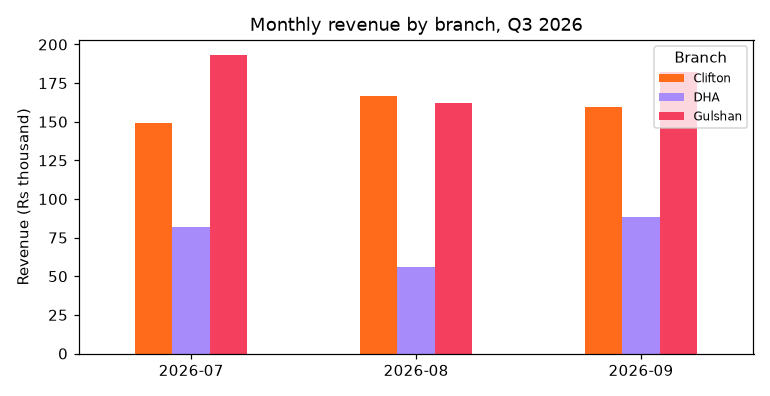

In [6]:
from IPython.display import Image, display
display(Image(filename='session-11_problem_sales_analysis.png'))  # chart saved by the cell above

## Example: `session-11_project_student_report.py`

In [7]:
"""
Session 11 · Mini project: an automated class performance report
----------------------------------------------------------------
Inputs (three tables, as a department would really have them):
  students   - roll, name, section
  marks      - long format: one row per (roll, subject, assessment, score)
  attendance - roll, classes_attended (out of 40)
The report:
  1. reshapes marks from long to wide with pivot_table,
  2. computes weighted totals (quiz 20 %, midterm 30 %, final 50 %),
  3. merges attendance, assigns grades with pd.cut, flags students at risk,
  4. summarises by section and subject, and exports report.csv,
  5. draws grade-distribution and section-comparison charts.
Run:  python session-11_project_student_report.py
"""
import numpy as np
import pandas as pd

pd.set_option("display.width", 120)
rng = np.random.default_rng(2026)
names = ["Ayesha", "Omar", "Hira", "Bilal", "Zainab", "Danish", "Mehwish", "Usman", "Sara", "Hamza",
         "Iqra", "Fahad", "Noor", "Saad", "Anum", "Taha"]
students = pd.DataFrame({"roll": [f"AI-{i:02d}" for i in range(1, 17)], "name": names,
                         "section": ["A"] * 8 + ["B"] * 8})
subjects, weights = ["Python", "Statistics", "Databases"], {"quiz": 0.2, "midterm": 0.3, "final": 0.5}
ability = dict(zip(students["roll"], rng.normal(70, 12, len(students))))
rows = [(r, s, a, float(np.clip(ability[r] + rng.normal(0, 8), 20, 100)))
        for r in students["roll"] for s in subjects for a in weights]
marks = pd.DataFrame(rows, columns=["roll", "subject", "assessment", "score"]).round(0)
# attendance loosely follows ability (students who attend tend to score better), plus noise
attended = [int(np.clip(round(14 + 0.28 * ability[r] + rng.normal(0, 3)), 20, 40)) for r in students["roll"]]
attendance = pd.DataFrame({"roll": students["roll"], "attended": attended})
print("marks table (long format):", marks.shape, "\n", marks.head(4).to_string(index=False))

# 1. long -> wide: one row per student and subject, assessments as columns
wide = marks.pivot_table(index=["roll", "subject"], columns="assessment", values="score").reset_index()
wide["total"] = sum(wide[a] * w for a, w in weights.items())

# 2. one row per student: subjects as columns + overall average
per_student = wide.pivot_table(index="roll", columns="subject", values="total").round(1)
per_student["average"] = per_student[subjects].mean(axis=1).round(1)

# 3. merge names, sections and attendance
report = (students.merge(per_student.reset_index(), on="roll")
                  .merge(attendance, on="roll"))
report["attendance_%"] = (report["attended"] / 40 * 100).round(0)
report["grade"] = pd.cut(report["average"], bins=[0, 50, 55, 70, 85, 100], labels=["F", "D", "C", "B", "A"], right=False)
report["at_risk"] = (report["average"] < 55) | (report["attendance_%"] < 75)
report = report.sort_values("average", ascending=False).reset_index(drop=True)
report.index += 1                                            # rank starting at 1
print("\nClass report (ranked):\n", report.drop(columns=["attended"]).to_string())

# 4. summaries
print("\nSection summary:\n", report.groupby("section").agg(students=("roll", "count"),
      mean_avg=("average", "mean"), best=("average", "max"), at_risk=("at_risk", "sum")).round(1))
print("\nSubject means by section:\n", report.groupby("section")[subjects].mean().round(1))
print("\nGrade distribution:", report["grade"].value_counts().reindex(list("ABCDF")).to_dict())
print("Students at risk:", report.loc[report["at_risk"], ["name", "average", "attendance_%"]].to_dict("records"))
corr = report["attendance_%"].corr(report["average"])
print(f"Correlation between attendance and average: r = {corr:.2f}")

report.to_csv("report.csv", index_label="rank")
print("\nExported report.csv")

# 5. charts
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.4))
counts = report["grade"].value_counts().reindex(list("ABCDF"), fill_value=0)
a1.bar(counts.index, counts.values, color=["#FF6B1A", "#FCD34D", "#A78BFA", "#F43F5E", "#6B7280"])
a1.set_title("Grade distribution"); a1.set_ylabel("students")
report.boxplot(column="average", by="section", ax=a2, grid=False)
a2.set_title("Average mark by section"); a2.set_xlabel("section"); fig.suptitle("")
fig.tight_layout(); fig.savefig("session-11_project_student_report.png", dpi=110)
print("Chart saved: session-11_project_student_report.png")

marks table (long format): (144, 4) 
  roll    subject assessment  score
AI-01     Python       quiz   57.0
AI-01     Python    midterm   65.0
AI-01     Python      final   59.0
AI-01 Statistics       quiz   49.0

Class report (ranked):
      roll     name section  Databases  Python  Statistics  average  attendance_% grade  at_risk
1   AI-04    Bilal       A       96.5    93.7        94.0     94.7          88.0     A    False
2   AI-12    Fahad       B       77.9    78.9        83.3     80.0          92.0     B    False
3   AI-05   Zainab       A       74.5    77.2        77.9     76.5         100.0     B    False
4   AI-11     Iqra       B       77.2    82.0        69.2     76.1          92.0     B    False
5   AI-02     Omar       A       81.8    79.5        66.8     76.0         100.0     B    False
6   AI-08    Usman       A       69.2    74.2        76.4     73.3          92.0     B    False
7   AI-15     Anum       B       67.8    68.8        80.0     72.2          80.0     B    

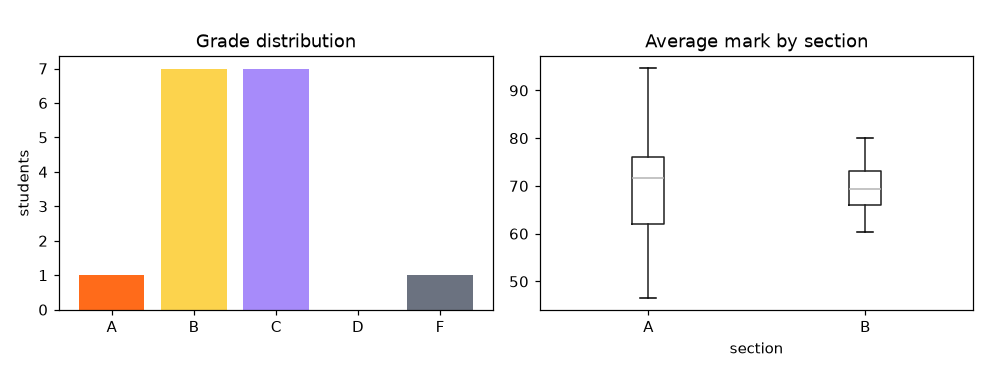

In [8]:
from IPython.display import Image, display
display(Image(filename='session-11_project_student_report.png'))  # chart saved by the cell above